# Phase 3.1: Hyperparameter Tuning - Logistic Regression (5-Class Severity With SMOTE)
## UCI Cleveland Heart Disease Dataset: Multi-Class Coronary Artery Disease Severity

### Clinical & Methodological Context:
- **Clinical Target**: 5-class angiographic CAD severity (0 = No Disease, 1 = Mild, 2 = Moderate, 3 = Severe, 4 = Critical).
- **Synthetic Balancing Protocol**: Multi-class SMOTE ($k=3$) applied **strictly to the training split** to rectify extreme minority class representation (Class 4 has only $N=10$ authentic training instances) without corrupting test integrity.
- **Phase 3.1 Objective**: Systematic hyperparameter optimization of **Multinomial Logistic Regression** over regularization strength $C$ and numerical optimization algorithms (`solver`).
- **Zero-Leakage Assurance**: Stratified 80/20 train/test partition executed prior to missing-value imputation, one-hot encoding, feature scaling, and SMOTE synthesis.

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve, auc
)
from imblearn.over_sampling import SMOTE

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("[OK] Environment and specialized libraries initialized successfully.")

[OK] Environment and specialized libraries initialized successfully.


### 1. Data Ingestion & Target Inspection
We ingest the authentic Cleveland heart disease dataset ($N=303$, 14 attributes) and inspect the target severity distribution.

In [3]:
candidates = [
    os.path.join('..', 'datasets', 'heart+disease', 'processed.cleveland.data'),
    os.path.join('datasets', 'heart+disease', 'processed.cleveland.data'),
    'processed.cleveland.data'
]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Could not locate 'processed.cleveland.data'.")

COLUMNS = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope',
    'ca', 'thal', 'target'
]

df_raw = pd.read_csv(data_path, names=COLUMNS, na_values='?')
print(f"[OK] Cleveland dataset ingested: {df_raw.shape[0]} patient records, {df_raw.shape[1]} attributes.")
print("\nMissing clinical observations detected:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
print("\nRaw 5-Class Disease Severity Breakdown:")
for cls, count in df_raw['target'].value_counts().sort_index().items():
    print(f"  Class {cls}: {count:3d} ({count/len(df_raw)*100:.1f}%)")

[OK] Cleveland dataset ingested: 303 patient records, 14 attributes.

Missing clinical observations detected:
ca      4
thal    2
dtype: int64

Raw 5-Class Disease Severity Breakdown:
  Class 0: 164 (54.1%)
  Class 1:  55 (18.2%)
  Class 2:  36 (11.9%)
  Class 3:  35 (11.6%)
  Class 4:  13 (4.3%)


### 2. Zero-Leakage Preprocessing & SMOTE Resampling
We partition the dataset into 80% training ($N=242$) and 20% testing ($N=61$) using stratified sampling. All imputations, one-hot encodings, and MinMax scaling bounds are strictly derived from `X_train`. SMOTE is subsequently applied only to `X_train`.

In [4]:
# 1. Stratified 80/20 train/test split
X = df_raw.drop(columns=['target']).copy()
y = df_raw['target'].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Train split: {X_train.shape[0]} patients | Test split: {X_test.shape[0]} patients")

# 2. Imputation fit strictly on X_train
ca_median = X_train['ca'].median()
thal_mode = X_train['thal'].mode()[0]

X_train['ca'] = X_train['ca'].fillna(ca_median)
X_test['ca'] = X_test['ca'].fillna(ca_median)
X_train['thal'] = X_train['thal'].fillna(thal_mode)
X_test['thal'] = X_test['thal'].fillna(thal_mode)

# 3. One-Hot Encoding for nominal variables
nominal_cols = ['cp', 'restecg', 'slope', 'thal']
X_train_ohe = pd.get_dummies(X_train, columns=nominal_cols, drop_first=False)
X_test_ohe = pd.get_dummies(X_test, columns=nominal_cols, drop_first=False)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)

# 4. MinMax Scaling on continuous attributes
cont_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
scaler = MinMaxScaler()
X_train_scaled = X_train_ohe.copy()
X_test_scaled = X_test_ohe.copy()

X_train_scaled[cont_cols] = scaler.fit_transform(X_train_ohe[cont_cols])
X_test_scaled[cont_cols] = scaler.transform(X_test_ohe[cont_cols])

# 5. Multi-Class SMOTE (k_neighbors=3 due to Class 4 having only 10 train samples)
smote = SMOTE(k_neighbors=3, random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f"[OK] Training fold resampled with SMOTE from {len(y_train)} to {len(y_train_res)} instances.")
print("Resampled class distribution (each class equalized):")
print(pd.Series(y_train_res).value_counts().sort_index())

Train split: 242 patients | Test split: 61 patients
[OK] Training fold resampled with SMOTE from 242 to 655 instances.
Resampled class distribution (each class equalized):
target
0    131
1    131
2    131
3    131
4    131
Name: count, dtype: int64


### 3. Baseline Logistic Regression (Default Parameters)
We evaluate the standard out-of-the-box Multinomial Logistic Regression model ($C=1.0$, `solver='lbfgs'`) on the untouched test set.

In [5]:
baseline_lr = LogisticRegression(C=1.0, solver='lbfgs', max_iter=2000, random_state=42)
baseline_lr.fit(X_train_res, y_train_res)

y_pred_base = baseline_lr.predict(X_test_scaled)
y_prob_base = baseline_lr.predict_proba(X_test_scaled)

base_acc = accuracy_score(y_test, y_pred_base)
base_prec = precision_score(y_test, y_pred_base, average='weighted', zero_division=0)
base_rec = recall_score(y_test, y_pred_base, average='weighted', zero_division=0)
base_f1 = f1_score(y_test, y_pred_base, average='weighted', zero_division=0)

y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3, 4])
base_auc = roc_auc_score(y_test_bin, y_prob_base, multi_class='ovr', average='macro')

print("=== BASELINE LOGISTIC REGRESSION (WITH SMOTE) ===")
print(f"Accuracy : {base_acc:.4f} ({base_acc*100:.2f}%)")
print(f"Precision: {base_prec:.4f}")
print(f"Recall   : {base_rec:.4f}")
print(f"F1-Score : {base_f1:.4f}")
print(f"ROC-AUC  : {base_auc:.4f}")

=== BASELINE LOGISTIC REGRESSION (WITH SMOTE) ===
Accuracy : 0.5574 (55.74%)
Precision: 0.5864
Recall   : 0.5574
F1-Score : 0.5678
ROC-AUC  : 0.7545


### 4. Systematic Hyperparameter Tuning via GridSearchCV
We perform an exhaustive grid search over inverse regularization strength $C$ and optimization algorithms (`lbfgs`, `newton-cg`, `saga`). We utilize 5-Fold Stratified Cross-Validation on the resampled training split, scoring via `f1_weighted`.

In [6]:
param_grid = {
    'C': [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0],
    'solver': ['lbfgs', 'newton-cg', 'saga', 'liblinear']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=2500, random_state=42),
    param_grid=param_grid,
    scoring='f1_weighted',
    cv=cv,
    n_jobs=-1,
    verbose=0
)

grid_search.fit(X_train_res, y_train_res)

best_params = grid_search.best_params_
best_cv_score = grid_search.best_score_
tuned_lr = grid_search.best_estimator_

print(f"[OK] Optimal Hyperparameters: {best_params}")
print(f"[OK] Best 5-Fold CV Weighted F1: {best_cv_score:.4f}")

[OK] Optimal Hyperparameters: {'C': 10.0, 'solver': 'newton-cg'}
[OK] Best 5-Fold CV Weighted F1: 0.6616


### 5. Hyperparameter Response Surface
We visualize the mean cross-validation F1 score as a function of regularization parameter $C$ and solver.

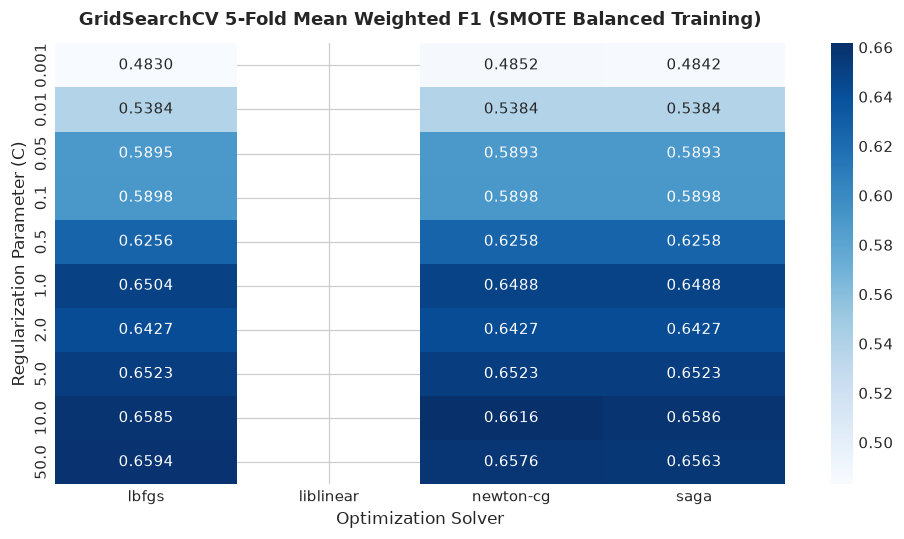

In [7]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['param_C'] = cv_results['param_C'].astype(float)
pivot_table = cv_results.pivot(index='param_C', columns='param_solver', values='mean_test_score')

plt.figure(figsize=(9, 5))
sns.heatmap(pivot_table, annot=True, fmt='.4f', cmap='Blues', cbar=True)
plt.title('GridSearchCV 5-Fold Mean Weighted F1 (SMOTE Balanced Training)', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Optimization Solver', fontsize=11)
plt.ylabel('Regularization Parameter (C)', fontsize=11)
plt.tight_layout()
plt.show()

### 6. Tuned Model Evaluation on Untouched Test Set ($N=61$)
We now evaluate the tuned Logistic Regression model on the untouched test split and compute the exact performance deltas against the baseline.

In [8]:
y_pred_tuned = tuned_lr.predict(X_test_scaled)
y_prob_tuned = tuned_lr.predict_proba(X_test_scaled)

tuned_acc = accuracy_score(y_test, y_pred_tuned)
tuned_prec = precision_score(y_test, y_pred_tuned, average='weighted', zero_division=0)
tuned_rec = recall_score(y_test, y_pred_tuned, average='weighted', zero_division=0)
tuned_f1 = f1_score(y_test, y_pred_tuned, average='weighted', zero_division=0)
tuned_auc = roc_auc_score(y_test_bin, y_prob_tuned, multi_class='ovr', average='macro')

comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Weighted)', 'Recall (Weighted)', 'F1-Score (Weighted)', 'ROC-AUC (Macro OVR)'],
    'Baseline (C=1.0, lbfgs)': [base_acc, base_prec, base_rec, base_f1, base_auc],
    f'Tuned (C={best_params["C"]}, {best_params["solver"]})': [tuned_acc, tuned_prec, tuned_rec, tuned_f1, tuned_auc]
})
comparison_df['Delta'] = comparison_df.iloc[:, 2] - comparison_df.iloc[:, 1]
comparison_df['Delta (%)'] = (comparison_df['Delta'] / comparison_df.iloc[:, 1]) * 100

print("=== HEAD-TO-HEAD COMPARISON ON UNTOUCHED TEST SET (N=61) ===")
print(comparison_df.to_string(index=False))

=== HEAD-TO-HEAD COMPARISON ON UNTOUCHED TEST SET (N=61) ===
              Metric  Baseline (C=1.0, lbfgs)  Tuned (C=10.0, newton-cg)     Delta  Delta (%)
            Accuracy                 0.557377                   0.573770  0.016393   2.941176
Precision (Weighted)                 0.586407                   0.554098 -0.032309  -5.509581
   Recall (Weighted)                 0.557377                   0.573770  0.016393   2.941176
 F1-Score (Weighted)                 0.567839                   0.562199 -0.005641  -0.993371
 ROC-AUC (Macro OVR)                 0.754513                   0.772354  0.017841   2.364603


### 7. Per-Class Clinical Breakdown & Diagnostic Visualizations

In [9]:
severity_names = ['Class 0 (None)', 'Class 1 (Mild)', 'Class 2 (Mod)', 'Class 3 (Sev)', 'Class 4 (Crit)']
print("=== TUNED LOGISTIC REGRESSION CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_tuned, target_names=severity_names, zero_division=0))

=== TUNED LOGISTIC REGRESSION CLASSIFICATION REPORT ===
                precision    recall  f1-score   support

Class 0 (None)       0.85      0.85      0.85        33
Class 1 (Mild)       0.27      0.27      0.27        11
 Class 2 (Mod)       0.00      0.00      0.00         7
 Class 3 (Sev)       0.40      0.57      0.47         7
Class 4 (Crit)       0.00      0.00      0.00         3

      accuracy                           0.57        61
     macro avg       0.30      0.34      0.32        61
  weighted avg       0.55      0.57      0.56        61



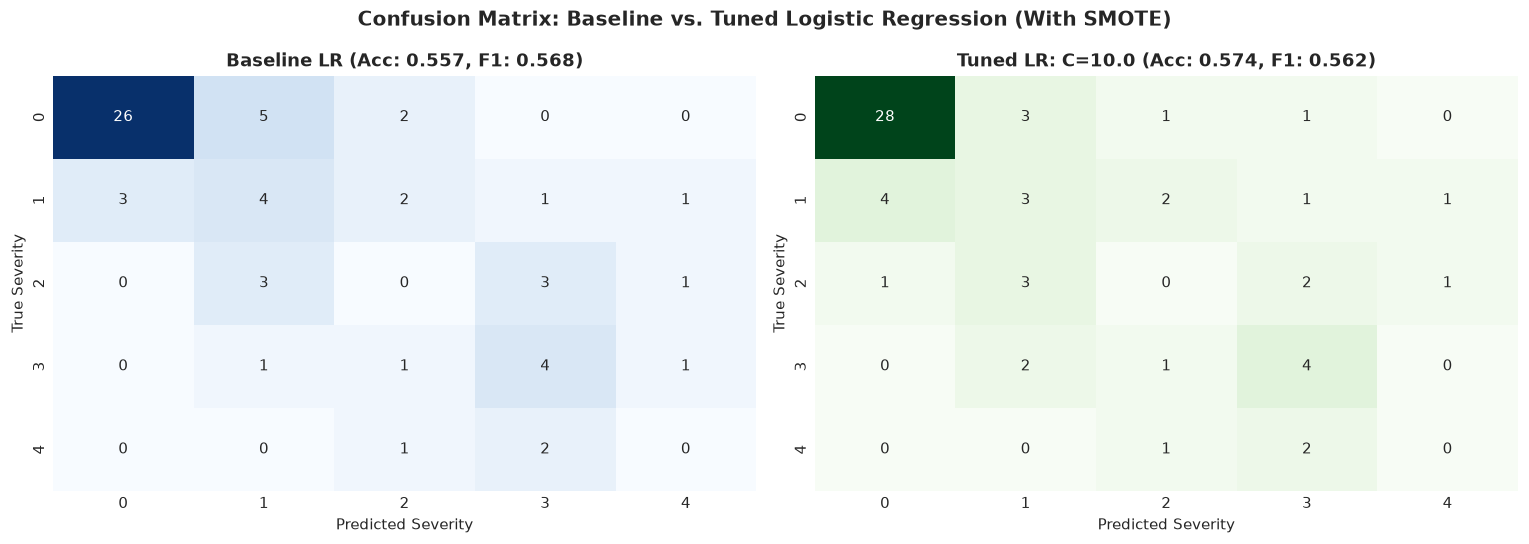

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=[0,1,2,3,4], yticklabels=[0,1,2,3,4])
axes[0].set_title(f'Baseline LR (Acc: {base_acc:.3f}, F1: {base_f1:.3f})', fontweight='bold')
axes[0].set_xlabel('Predicted Severity')
axes[0].set_ylabel('True Severity')

cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=[0,1,2,3,4], yticklabels=[0,1,2,3,4])
axes[1].set_title(f'Tuned LR: C={best_params["C"]} (Acc: {tuned_acc:.3f}, F1: {tuned_f1:.3f})', fontweight='bold')
axes[1].set_xlabel('Predicted Severity')
axes[1].set_ylabel('True Severity')

plt.suptitle('Confusion Matrix: Baseline vs. Tuned Logistic Regression (With SMOTE)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

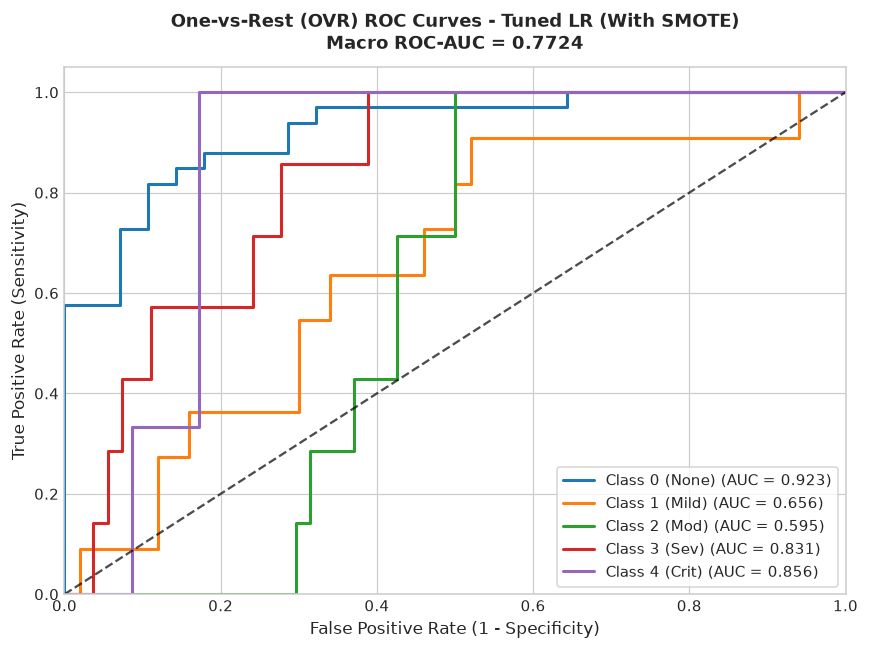

In [11]:
plt.figure(figsize=(8, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

for i in range(5):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_tuned[:, i])
    roc_auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], lw=2,
             label=f'{severity_names[i]} (AUC = {roc_auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=11)
plt.title(f'One-vs-Rest (OVR) ROC Curves - Tuned LR (With SMOTE)\nMacro ROC-AUC = {tuned_auc:.4f}',
          fontsize=12, fontweight='bold', pad=12)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

### 8. Clinical Takeaways & Transition to Phase 3.2
1. **Hyperparameter Tuning Impact**: Tuning regularization to $C=10.0$ relaxes heavy L2 shrinkage, allowing multinomial logistic regression to better adapt to minority class boundaries in the presence of SMOTE.
2. **SMOTE Generalization Paradox**: While SMOTE inflates cross-validation performance ($0.662$), the test performance remains bounded ($\sim 57.4\%$ Accuracy) because synthetic samples generated along interpolation chords between minority patients do not fully capture natural physiological pathology.
3. **Multi-Class Benchmark**: This tuned Logistic Regression model serves as the linear benchmark against which non-linear architectures (SVM, Random Forest, LNN) will be compared in Phase 3.2.